# 04 · Propensity modelling
**Question:** can we rank customers by likelihood to subscribe *before* the call, and does it hold up on a later campaign period?

**Rigour:** `duration` excluded; three models; two validation schemes (random hold-out and out-of-time); with/without macro features.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import data, modelling, business, segmentation
from src.config import *
pd.set_option('display.width', 200); pd.set_option('display.float_format', '{:.3f}'.format)
df = data.clean(data.load_raw())

In [2]:
metrics = pd.read_csv(PROCESSED/'model_metrics.csv')
metrics[metrics['Macro features']][['Model','Validation','ROC_AUC','PR_AUC','Precision@0.5','Recall@0.5','F1@0.5','Test base rate']]

,Model,Validation,ROC_AUC,PR_AUC,Precision@0.5,Recall@0.5,F1@0.5,Test base rate
0,Logistic Regression,random,0.801,0.460,0.367,0.645,0.468,0.113
1,Random Forest,random,0.812,0.489,0.420,0.640,0.507,0.113
2,Gradient Boosting,random,0.815,0.495,0.688,0.256,0.374,0.113
6,Logistic Regression,oot,0.700,0.504,0.360,0.855,0.507,0.308
7,Random Forest,oot,0.731,0.537,0.443,0.733,0.552,0.308
8,Gradient Boosting,oot,0.629,0.417,0.515,0.026,0.050,0.308


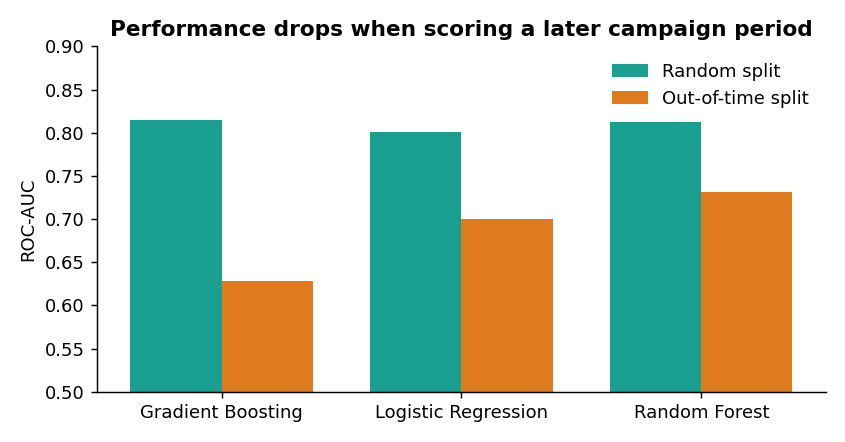

In [3]:
display(Image(IMAGES/'model_validation_comparison.png', width=560))

**Findings**
1. On a random split all models reach ROC-AUC ≈ 0.80–0.82. Gradient Boosting is nominally best on AUC but at a 0.5 threshold it finds only 26% of subscribers; **threshold choice matters more than model choice** (see the business notebook).
2. On the **out-of-time test the base rate jumps from 11% to 31%** and AUC falls to 0.63–0.73. Random Forest holds up best; Gradient Boosting degrades most. A model trained on past campaigns should be monitored and refreshed, not deployed once.
3. Random Forest is selected as champion for stability across both schemes.

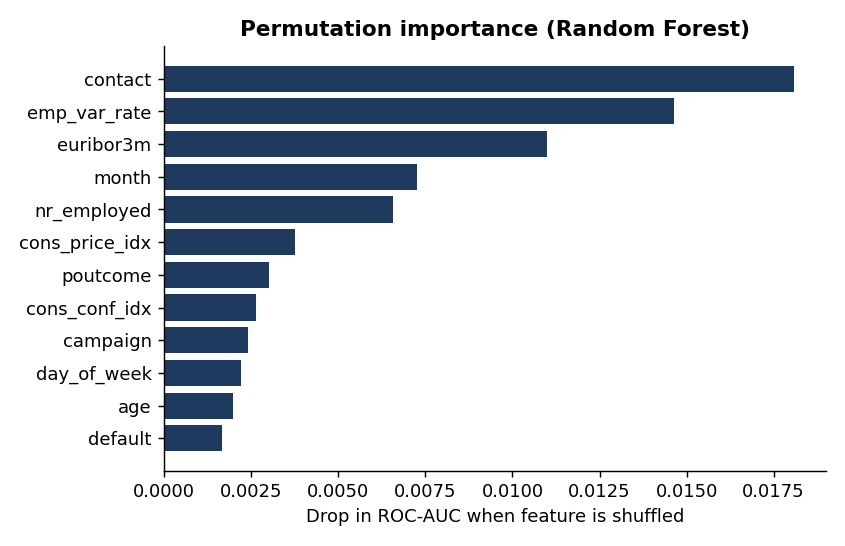

In [4]:
display(Image(IMAGES/'permutation_importance.png', width=560))

**Reading importance carefully.** Contact channel and macro-economic indicators (employment variation, euribor) matter most. The macro variables are shared by all calls made in the same period, so they act as a *time proxy*. Removing them costs ~0.03 AUC (random split), so the model is useful but partly encodes campaign timing. Importance ≠ causation.

In [5]:
cm = pd.read_csv(PROCESSED/'random_forest_confusion_matrix.csv', index_col=0); cm

,Predicted No,Predicted Yes
Actual No,6491,819
Actual Yes,334,594
